# 03 · Cohortes Comparables, Estructuras Motoras y Definición Normativa de `Hardware OK`

**Ticket 4.5 (Issue #31)** · Consolida los pasos analíticos **4.3, 4.4 y 4.5** acordados con el experto clínico (Dr. Tiberio).

**Decisiones vinculadas:** [DEC-016](file:///docs/decisiones.md), [DEC-026](file:///docs/decisiones.md), [DEC-029](file:///docs/decisiones.md), [DEC-030](file:///docs/decisiones.md), [DEC-031](file:///docs/decisiones.md)

> **Privacidad de datos (DEC-001 / DEC-005):** Este notebook consume el módulo oficial `src.features.build_hardware_ok` y reporta exclusivamente **estadísticos agregados** (conteos, medias, DE, medianas, IQR, tamaños de efecto, IC 95% y valores $q_{\text{FDR}}$). Ninguna celda imprime ni exporta filas o identificadores individuales de pacientes.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.features.build_hardware_ok import build_hardware_ok_pipeline

sns.set_theme(style="whitegrid", font="sans-serif")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

hw_ok_df, reports = build_hardware_ok_pipeline()
print(
    f"Muestra analítica prematuros (fit_sample): n = {len(hw_ok_df)} (qc_ok: n = {int(hw_ok_df['qc_ok'].sum())})"
)

Muestra analítica prematuros (fit_sample): n = 209 (qc_ok: n = 168)


## 1. Grupos Comparables, Sensibilidad RCIU-Fenton y Tabla 1 Descriptiva (Paso 4.3 / DEC-029)

Comparamos el grupo de **Referencia a Término (`ubicac == 3`, $\text{EG} \ge 37\text{ sem}$, $\text{peso} \ge 2500\text{ g}$)** con resonancia magnética ($n = 37$, y sensibilidad sin los 9 sujetos con `rciu_fenton_ref == True`, $n = 28$) frente al grupo de **Prematuros `< 1801 g` (`fit_sample`, $n = 209$, y submuestra `qc_ok`, $n = 168$)** en variables perinatales (`BIRTH`) y sociodemográficas (`SCB`).

In [2]:
tabla1 = reports["tabla1_cohortes"]
cont_cols = [
    "variable",
    "n_ref_mri",
    "ref_mri_mean_or_pct",
    "ref_mri_sd",
    "ref_mri_median",
    "n_ref_no_rciu",
    "ref_no_rciu_mean_or_pct",
    "n_preterm_fit",
    "preterm_fit_mean_or_pct",
    "preterm_fit_sd",
    "hedges_g_pre_vs_ref",
    "p_value_welch",
    "p_value_mwu",
]
print(
    "=== TABLA 1A: VARIABLES CONTINUAS (REFERENCIA CON RM vs. PREMATUROS FIT_SAMPLE) ==="
)
display(tabla1.loc[tabla1["kind"] == "continuous", cont_cols].round(3))

cat_cols = [
    "variable",
    "n_ref_mri",
    "ref_mri_mean_or_pct",
    "n_ref_no_rciu",
    "ref_no_rciu_mean_or_pct",
    "n_preterm_fit",
    "preterm_fit_mean_or_pct",
    "n_preterm_qc",
    "preterm_qc_mean_or_pct",
]
print("\n=== TABLA 1B: VARIABLES CATEGÓRICAS (% POR NIVEL) ===")
display(tabla1.loc[tabla1["kind"] == "categorical_pct", cat_cols].round(1))

=== TABLA 1A: VARIABLES CONTINUAS (REFERENCIA CON RM vs. PREMATUROS FIT_SAMPLE) ===


,variable,n_ref_mri,ref_mri_mean_or_pct,ref_mri_sd,ref_mri_median,n_ref_no_rciu,ref_no_rciu_mean_or_pct,n_preterm_fit,preterm_fit_mean_or_pct,preterm_fit_sd,hedges_g_pre_vs_ref,p_value_welch,p_value_mwu
0,BIRTH_peso5,37,3032.081,343.715,3015.0,28,3155.179,209,1558.110,233.073,-5.820,0.000,0.000
1,BIRTH_ballar5,37,38.973,0.986,39.0,28,39.036,209,33.077,2.545,-2.470,0.000,0.000
2,BIRTH_talla5,36,488.333,20.494,490.0,27,495.556,207,407.053,31.650,-2.675,0.000,0.000
3,BIRTH_pc5,28,340.571,11.249,340.0,19,343.474,166,299.205,17.584,-2.447,0.000,0.000
4,SCB_agemother,37,24.378,5.454,22.0,28,24.571,208,28.274,5.704,0.685,0.000,0.000
5,SCB_percap1,37,117106.757,82783.675,100000.0,28,112236.310,208,84129.808,56381.782,-0.539,0.025,0.025



=== TABLA 1B: VARIABLES CATEGÓRICAS (% POR NIVEL) ===


,variable,n_ref_mri,ref_mri_mean_or_pct,n_ref_no_rciu,ref_no_rciu_mean_or_pct,n_preterm_fit,preterm_fit_mean_or_pct,n_preterm_qc,preterm_qc_mean_or_pct
6,BIRTH_sexo5==1,37,51.4,28,53.6,209,58.4,168,60.1
7,BIRTH_sexo5==2,37,48.6,28,46.4,209,41.6,168,39.9
8,BIRTH_cesarea==0,37,100.0,28,100.0,208,30.3,168,30.4
9,BIRTH_cesarea==1,37,0.0,28,0.0,208,69.7,168,69.6
10,BIRTH_RCIUFenton==0,37,75.7,28,100.0,209,54.1,168,51.8
11,BIRTH_RCIUFenton==1,37,24.3,28,0.0,209,45.9,168,48.2
12,SCB_civilstatus==1,37,75.7,28,75.0,209,86.6,168,85.7
13,SCB_civilstatus==2,37,24.3,28,25.0,209,13.4,168,14.3
14,SCB_nivm1==1,37,21.6,28,28.6,209,16.7,168,18.5
15,SCB_nivm1==2,37,59.5,28,53.6,209,57.4,168,56.0


## 2. Caracterización del NHPT, Concordancia Bimanual y Normas de Mathiowetz (1985)

Describimos `NHPT_promedioMD`, `NHPT_promedioMND`, el promedio bimanual `nhpt_mean` y el puntaje estandarizado contra la referencia local (`z_nhpt_ref`, signo invertido: mayor = mejor destreza). Verificamos además la concordancia entre ambas manos ($r = 0.66$) y el desplazamiento frente a las normas de adultos jóvenes (20–24 años) de Mathiowetz et al. (1985).

In [3]:
nhpt_df = reports["nhpt_por_grupo"]
concordance = reports["calibracion_hardware_ok"]["nhpt_bimanual_concordance"]
print("=== CONCORDANCIA BIMANUAL (MD vs. MND) ===")
for k, v in concordance.items():
    print(f"  {k:28s}: {v:.4f}" if isinstance(v, float) else f"  {k:28s}: {v}")

print("\n=== CARACTERIZACIÓN DE NHPT POR GRUPO Y CONTRASTE CON MATHIOWETZ (1985) ===")
nhpt_cols_show = [
    "group",
    "metric",
    "n",
    "mean",
    "sd",
    "median",
    "iqr",
    "hedges_g_vs_ref",
    "cliffs_delta_vs_ref",
    "p_welch_vs_ref",
    "diff_vs_mathiowetz_1985_s",
]
display(nhpt_df[nhpt_cols_show].round(3))

=== CONCORDANCIA BIMANUAL (MD vs. MND) ===
  n_both_hands_total          : 483
  pearson_r_total             : 0.6557
  pearson_p_total             : 0.0000
  spearman_rho_total          : 0.4949
  pearson_r_fit_sample        : 0.7424
  pearson_p_fit_sample        : 0.0000
  mean_diff_mnd_minus_md_s    : 1.7204

=== CARACTERIZACIÓN DE NHPT POR GRUPO Y CONTRASTE CON MATHIOWETZ (1985) ===


,group,metric,n,mean,sd,median,iqr,hedges_g_vs_ref,cliffs_delta_vs_ref,p_welch_vs_ref,diff_vs_mathiowetz_1985_s
0,referencia_total_nhpt,NHPT_promedioMD,49,17.633,1.439,17.500,2.000,0.000,0.000,1.000,1.633
1,referencia_total_nhpt,NHPT_promedioMND,49,19.888,2.486,19.000,3.000,0.000,0.000,1.000,2.938
2,referencia_total_nhpt,nhpt_mean,49,18.760,1.564,18.500,2.500,0.000,0.000,1.000,2.285
3,referencia_total_nhpt,z_nhpt_ref,49,-0.176,1.055,0.000,1.686,0.000,0.000,1.000,NaN
4,referencia_mri_nhpt,NHPT_promedioMD,36,17.750,1.481,17.500,2.000,0.080,0.045,0.716,1.750
5,referencia_mri_nhpt,NHPT_promedioMND,36,19.694,2.259,19.000,2.625,-0.080,-0.016,0.710,2.744
6,referencia_mri_nhpt,nhpt_mean,36,18.722,1.436,18.625,1.625,-0.025,0.012,0.908,2.247
7,referencia_mri_nhpt,z_nhpt_ref,36,-0.150,0.969,-0.084,1.096,0.025,-0.012,0.908,NaN
8,referencia_sin_rciu,NHPT_promedioMD,37,17.811,1.366,18.000,2.000,0.125,0.088,0.560,1.811
9,referencia_sin_rciu,NHPT_promedioMND,37,19.919,2.513,19.000,3.000,0.012,0.012,0.955,2.969


## 3. Contraste Anatómico Término vs. Prematuros en Valores Absolutos (Paso 4.4 / DEC-016 / DEC-030)

Siguiendo estrictamente **DEC-016**, comparamos el `icv` y las **80 ROIs motoras en valores absolutos** (excluyendo las columnas `*_icvadj` dado que el ICV es un desenlace de la prematurez). Reportamos $g$ de Hedges, $\delta$ de Cliff, valores $p$ y $q_{\text{FDR}}$ de Benjamini-Hochberg, junto con las sensibilidades `qc_ok` y `no_rciu`.

ROIs del atlas principal con q_FDR < 0.05 (Welch o MWU): 33 / 65

=== TOP 25 ESTRUCTURAS MOTORAS POR |g DE HEDGES| (VALORES ABSOLUTOS, PREMATUROS vs. TÉRMINO) ===


,roi,family,in_shortlist_18,mean_preterm,mean_ref,hedges_g,hedges_g_ci95_low,hedges_g_ci95_high,cliffs_delta,p_welch,q_fdr_welch_primary65,q_fdr_mwu_primary65,hedges_g_qc_ok,hedges_g_no_rciu
63,ba_rh_ba1_curv,brodmann_m1_s1,False,1.882000e-01,1.672000e-01,0.9053,0.5466,1.2640,0.5862,0.0000,0.0000,0.0000,0.9508,0.9876
80,cst_rh_vol,corticospinal_tract,True,1.039139e+03,1.257459e+03,-0.8218,-1.1789,-0.4647,-0.4800,0.0000,0.0002,0.0001,-0.7445,-0.8712
43,sub_rh_pallidum_vol,basal_ganglia,True,1.482836e+03,1.675887e+03,-0.7688,-1.1250,-0.4126,-0.3942,0.0011,0.0046,0.0012,-0.7006,-0.8332
1,sub_lh_caudate_vol,basal_ganglia,True,3.396453e+03,3.772392e+03,-0.7503,-1.1061,-0.3944,-0.3873,0.0001,0.0005,0.0013,-0.7881,-0.8966
23,ba_lh_ba1_curv,brodmann_m1_s1,False,1.875000e-01,1.702000e-01,0.7137,0.3585,1.0690,0.4326,0.0000,0.0000,0.0006,0.7942,0.7714
41,sub_rh_caudate_vol,basal_ganglia,True,3.646926e+03,4.013103e+03,-0.7049,-1.0600,-0.3498,-0.3739,0.0003,0.0017,0.0018,-0.7762,-0.8471
47,ba_rh_ba4a_curv,brodmann_m1_s1,False,1.329000e-01,1.164000e-01,0.6888,0.3339,1.0437,0.3911,0.0000,0.0000,0.0012,0.7262,0.7265
7,ba_lh_ba4a_curv,brodmann_m1_s1,False,1.345000e-01,1.198000e-01,0.6875,0.3326,1.0423,0.4032,0.0000,0.0000,0.0010,0.7480,0.7267
42,sub_rh_putamen_vol,basal_ganglia,True,6.054926e+03,6.514473e+03,-0.6275,-0.9815,-0.2735,-0.3480,0.0011,0.0046,0.0035,-0.6464,-0.6764
51,ba_rh_ba4p_curv,brodmann_m1_s1,False,1.155000e-01,1.032000e-01,0.6185,0.2647,0.9724,0.4132,0.0000,0.0000,0.0010,0.6461,0.6935


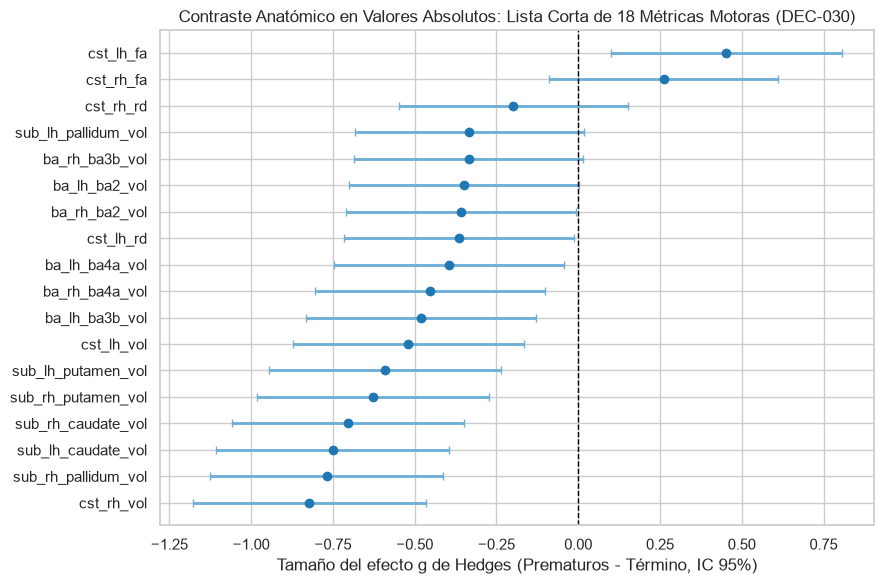

In [4]:
rois_df = reports["contraste_80_rois_absolutas"].copy()
prim_rois = rois_df.loc[rois_df["is_primary_atlas"]].copy()
prim_rois = prim_rois.reindex(
    prim_rois["hedges_g"].abs().sort_values(ascending=False).index
)

show_roi_cols = [
    "roi",
    "family",
    "in_shortlist_18",
    "mean_preterm",
    "mean_ref",
    "hedges_g",
    "hedges_g_ci95_low",
    "hedges_g_ci95_high",
    "cliffs_delta",
    "p_welch",
    "q_fdr_welch_primary65",
    "q_fdr_mwu_primary65",
    "hedges_g_qc_ok",
    "hedges_g_no_rciu",
]
print(
    f"ROIs del atlas principal con q_FDR < 0.05 (Welch o MWU): "
    f"{int(((prim_rois['q_fdr_welch_primary65'] < 0.05) | (prim_rois['q_fdr_mwu_primary65'] < 0.05)).sum())} / {len(prim_rois)}"
)
print(
    "\n=== TOP 25 ESTRUCTURAS MOTORAS POR |g DE HEDGES| (VALORES ABSOLUTOS, PREMATUROS vs. TÉRMINO) ==="
)
display(prim_rois[show_roi_cols].head(25).round(4))

# Visualización agregada (Forest plot de las 18 estructuras de la lista corta de 3 dominios)
sl18_df = rois_df.loc[rois_df["in_shortlist_18"]].sort_values("hedges_g")
fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(sl18_df))
ax.errorbar(
    sl18_df["hedges_g"],
    y_pos,
    xerr=[
        sl18_df["hedges_g"] - sl18_df["hedges_g_ci95_low"],
        sl18_df["hedges_g_ci95_high"] - sl18_df["hedges_g"],
    ],
    fmt="o",
    color="#1f77b4",
    ecolor="#6baed6",
    elinewidth=2,
    capsize=3,
)
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(sl18_df["roi"])
ax.set_xlabel("Tamaño del efecto g de Hedges (Prematuros - Término, IC 95%)")
ax.set_title(
    "Contraste Anatómico en Valores Absolutos: Lista Corta de 18 Métricas Motoras (DEC-030)"
)
plt.tight_layout()
plt.show()

## 4. Asociación Estructura–NHPT en Prematuros y Calibración Normativa de `hardware_ok` (Paso 4.5 / DEC-031)

Evaluamos en prematuros (`fit_sample` $n = 209$ y `qc_ok` $n = 168$) la correlación parcial y regresión ajustada por `BIRTH_sexo5` entre las métricas seleccionadas (absolutas e `*_icvadj`) y el tiempo en NHPT (`nhpt_mean`). Finalmente, verificamos la distribución de `hardware_ok` (`hw_norm_score >= -1.0`) y sus variantes de sensibilidad para el Ticket #33 (`5.2`).

In [5]:
assoc_df = reports["asociacion_estructura_nhpt"].copy()
assoc_sorted = assoc_df.reindex(
    assoc_df["partial_r_fit"].abs().sort_values(ascending=False).index
)
assoc_cols = [
    "feature",
    "scale_type",
    "n_fit",
    "partial_r_fit",
    "partial_r_ci95_low_fit",
    "partial_r_ci95_high_fit",
    "p_value_fit",
    "q_fdr_fit",
    "ols_beta_s_per_sd_fit",
    "huber_beta_s_per_sd_fit",
    "partial_r_qc",
    "p_value_qc",
]
print("=== ASOCIACIÓN ESTRUCTURA-NHPT AJUSTADA POR SEXO (TOP 20 EN FIT_SAMPLE) ===")
display(assoc_sorted[assoc_cols].head(20).round(4))

cal_df = pd.DataFrame(reports["calibracion_hardware_ok"]["calibration_candidates"])
print("\n=== CALIBRACIÓN DE CRITERIOS CANDIDATOS PARA HARDWARE_OK (DEC-031) ===")
display(cal_df.round(1))

# Resumen agregado del dataframe de salida (sin mostrar filas individuales)
print("\n=== RESUMEN AGREGADO DE DATA/FEATURES/HARDWARE_OK.PARQUET ===")
summary_stats = (
    hw_ok_df[
        [
            "hw_norm_score",
            "hw_norm_score_vol12",
            "hw_norm_score_no_rciu",
            "n_impaired_structures",
            "nhpt_mean",
            "z_nhpt_ref",
        ]
    ]
    .describe()
    .T
)
display(summary_stats.round(3))

=== ASOCIACIÓN ESTRUCTURA-NHPT AJUSTADA POR SEXO (TOP 20 EN FIT_SAMPLE) ===


,feature,scale_type,n_fit,partial_r_fit,partial_r_ci95_low_fit,partial_r_ci95_high_fit,p_value_fit,q_fdr_fit,ols_beta_s_per_sd_fit,huber_beta_s_per_sd_fit,partial_r_qc,p_value_qc
43,ba_rh_ba2_curv,absolute_or_composite,209,0.3372,0.2109,0.4525,0.0000,0.0000,0.9263,0.3669,0.2940,0.0001
41,ba_rh_ba3b_curv,absolute_or_composite,209,0.2996,0.1705,0.4186,0.0000,0.0003,0.8245,0.2666,0.2270,0.0031
46,hw_norm_score,absolute_or_composite,209,-0.2886,-0.4086,-0.1588,0.0000,0.0004,-0.8557,-0.4605,-0.2027,0.0084
3,sub_rh_putamen_vol,absolute_or_composite,209,-0.2764,-0.3975,-0.1459,0.0001,0.0006,-0.8067,-0.2614,-0.2382,0.0019
44,hw_motor,absolute_or_composite,209,-0.2707,-0.3923,-0.1398,0.0001,0.0007,-0.7462,-0.3720,-0.1474,0.0565
47,hw_norm_score_vol12,absolute_or_composite,209,-0.2627,-0.3850,-0.1313,0.0001,0.0009,-0.7887,-0.4270,-0.1939,0.0118
21,sub_rh_putamen_vol_icvadj,icv_adjusted,209,-0.2613,-0.3837,-0.1299,0.0001,0.0009,-0.7192,-0.1949,-0.2061,0.0073
0,sub_lh_caudate_vol,absolute_or_composite,209,-0.2557,-0.3785,-0.1239,0.0002,0.0011,-0.7069,-0.3590,-0.2183,0.0045
18,sub_lh_caudate_vol_icvadj,icv_adjusted,209,-0.2471,-0.3707,-0.1149,0.0003,0.0017,-0.6822,-0.3363,-0.1973,0.0104
35,ba_lh_ba3b_curv,absolute_or_composite,209,0.2239,0.0907,0.3493,0.0011,0.0044,0.6155,0.1383,0.2349,0.0022



=== CALIBRACIÓN DE CRITERIOS CANDIDATOS PARA HARDWARE_OK (DEC-031) ===


,criterion,n_fit_total,n_fit_ok,pct_fit_ok,n_qc_total,n_qc_ok,pct_qc_ok
0,hardware_ok_main_3domain18_ge_m1sd,209,109,52.2,168,94,56.0
1,hardware_ok_no_rciu_3domain18_ge_m1sd,209,99,47.4,168,87,51.8
2,hardware_ok_vol12_ge_m1sd,209,93,44.5,168,79,47.0
3,hardware_ok_count_le2_of_12,209,93,44.5,168,78,46.4
4,rejected_strict_intersection_0_of_12,209,32,15.3,168,26,15.5



=== RESUMEN AGREGADO DE DATA/FEATURES/HARDWARE_OK.PARQUET ===


,count,mean,std,min,25%,50%,75%,max
hw_norm_score,209.0,-1.024,1.703,-10.610,-1.929,-0.955,0.116,3.162
hw_norm_score_vol12,209.0,-1.275,1.258,-5.811,-2.016,-1.241,-0.515,2.664
hw_norm_score_no_rciu,209.0,-1.184,1.833,-11.093,-2.155,-1.076,0.080,3.387
n_impaired_structures,209.0,3.483,3.029,0.000,1.000,3.000,5.000,12.000
nhpt_mean,209.0,19.170,2.752,14.500,17.700,18.500,20.000,35.750
z_nhpt_ref,209.0,-0.452,1.856,-11.635,-1.012,0.000,0.540,2.698
